# Task 68: Dynamic User Input Validation & Real-Time Processing

Validate clinical user inputs dynamically, resolve critical edge cases (missing attributes, malformed string types, out-of-bounds metrics, physiological conflicts), and benchmark microsecond vectorized input transformations.


=== DYNAMIC INPUT VALIDATION & EDGE CASE TEST RESULTS ===

--- Scenario 1: Clean Valid Patient ---
Validation latency: 102.72 µs | Probability: 0.5227

--- Scenario 2: Missing 7 Attributes ---
Validation latency: 69.40 µs | Probability: 0.5434
Warnings/Imputations (7): ['Missing sex: automatically imputed to default (1)', 'Missing fbs: automatically imputed to default (0)']

--- Scenario 3: Extreme Out-of-Bounds ---
Validation latency: 102.21 µs | Probability: 0.0018
Warnings/Imputations (10): ['age (145.0) exceeds maximum physiological bound 100.0: clipped to 100.0', 'Categorical cp (7) out of allowed set [0, 1, 2, 3]: clipped to 3']

--- Scenario 4: Malformed String Data ---
Validation latency: 77.93 µs | Probability: 0.0858
Errors handled (4): ["Invalid non-numeric value for chol ('elevated'): fallback to default (240.0)", "Invalid non-numeric value for fbs ('yes'): fallback to default (0)"]

--- Scenario 5: Physiological Conflict ---
Validation latency: 55.79 µs | Probability: 0.10

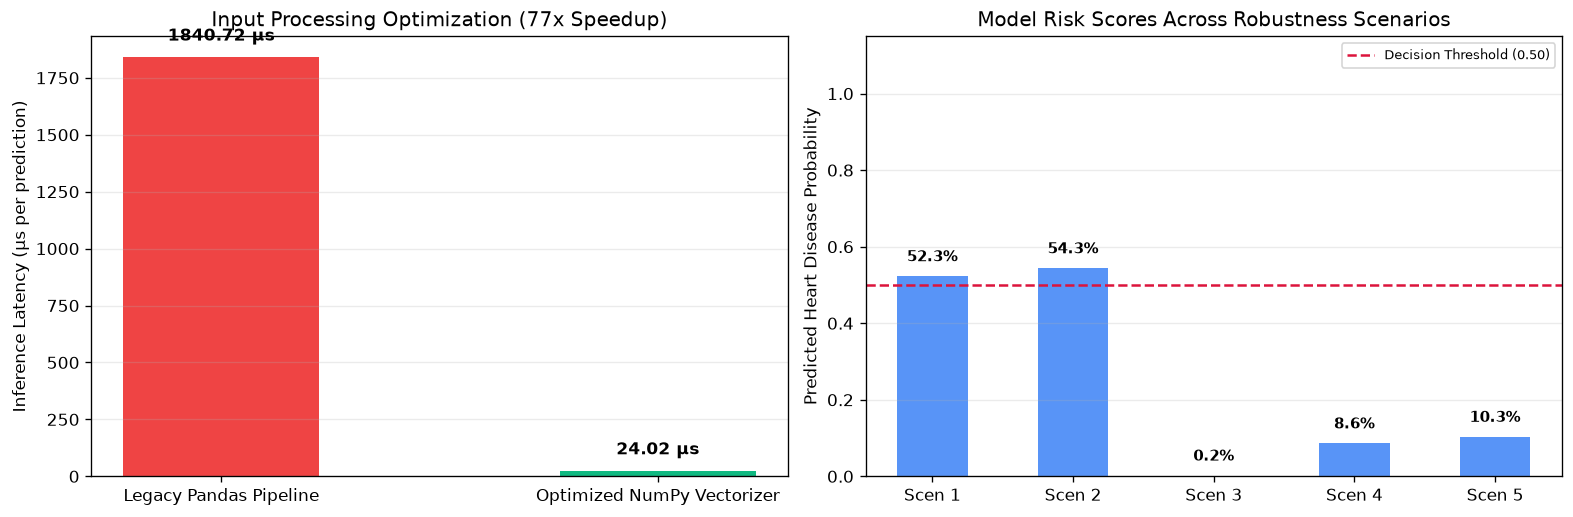

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("heart.csv"), Path("Task_68_Dynamic_Input_Validation/heart.csv"), Path("Heart_Disease_Tasks/Task_68_Dynamic_Input_Validation/heart.csv")]
data = pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if c in data]
X, y = data[features].to_numpy(float), data["target"].to_numpy(int)

# Stratified Split & Preprocessing
def stratified_split(X, y, test_size=0.2, seed=68):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for label in np.unique(y):
        idx = np.flatnonzero(y == label)
        rng.shuffle(idx)
        cut = int(round(len(idx) * (1 - test_size)))
        train_idx.extend(idx[:cut])
        test_idx.extend(idx[cut:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=68)
mu = X_train.mean(axis=0)
sd = np.where(X_train.std(axis=0) == 0, 1.0, X_train.std(axis=0))
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

class ScratchLogistic:
    def fit(self, X, y, lr=0.06, iters=1400, l2=0.02):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        n = len(y)
        for _ in range(iters):
            z = np.clip(X @ self.w + self.b, -35, 35)
            p = 1.0 / (1.0 + np.exp(-z))
            err = p - y
            self.w -= lr * ((X.T @ err) / n + l2 * self.w)
            self.b -= lr * err.mean()
        return self
    def predict_proba(self, X):
        z = np.clip(X @ self.w + self.b, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))
    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

model = ScratchLogistic().fit(X_train_s, y_train)

# Feature Specifications & Physiological Bounds
FEATURE_SPECS = {
    "age": {"type": float, "min": 18.0, "max": 100.0, "default": 55.0, "categorical": False},
    "sex": {"type": int, "allowed": [0, 1], "default": 1, "categorical": True},
    "cp": {"type": int, "allowed": [0, 1, 2, 3], "default": 0, "categorical": True},
    "trestbps": {"type": float, "min": 80.0, "max": 240.0, "default": 130.0, "categorical": False},
    "chol": {"type": float, "min": 100.0, "max": 600.0, "default": 240.0, "categorical": False},
    "fbs": {"type": int, "allowed": [0, 1], "default": 0, "categorical": True},
    "restecg": {"type": int, "allowed": [0, 1, 2], "default": 0, "categorical": True},
    "thalach": {"type": float, "min": 60.0, "max": 220.0, "default": 150.0, "categorical": False},
    "exang": {"type": int, "allowed": [0, 1], "default": 0, "categorical": True},
    "oldpeak": {"type": float, "min": 0.0, "max": 10.0, "default": 1.0, "categorical": False},
    "slope": {"type": int, "allowed": [0, 1, 2], "default": 1, "categorical": True},
    "ca": {"type": int, "allowed": [0, 1, 2, 3, 4], "default": 0, "categorical": True},
    "thal": {"type": int, "allowed": [0, 1, 2, 3], "default": 2, "categorical": True},
}

def validate_and_impute_input(raw, specs=FEATURE_SPECS):
    clean = {}
    warnings = []
    errors = []
    for feat, spec in specs.items():
        val = raw.get(feat, None)
        if val is None or val == "" or (isinstance(val, float) and np.isnan(val)):
            clean[feat] = float(spec["default"])
            warnings.append(f"Missing {feat}: automatically imputed to default ({spec['default']})")
            continue
        try:
            parsed = float(val)
        except (ValueError, TypeError):
            clean[feat] = float(spec["default"])
            errors.append(f"Invalid non-numeric value for {feat} ({val!r}): fallback to default ({spec['default']})")
            continue

        if spec["categorical"]:
            parsed_int = int(round(parsed))
            if parsed_int not in spec["allowed"]:
                closest = min(spec["allowed"], key=lambda a: abs(a - parsed_int))
                clean[feat] = float(closest)
                warnings.append(f"Categorical {feat} ({val}) out of allowed set {spec['allowed']}: clipped to {closest}")
            else:
                clean[feat] = float(parsed_int)
        else:
            if parsed < spec["min"]:
                clean[feat] = float(spec["min"])
                warnings.append(f"{feat} ({parsed}) below minimum physiological bound {spec['min']}: clipped to {spec['min']}")
            elif parsed > spec["max"]:
                clean[feat] = float(spec["max"])
                warnings.append(f"{feat} ({parsed}) exceeds maximum physiological bound {spec['max']}: clipped to {spec['max']}")
            else:
                clean[feat] = float(parsed)

    if "age" in clean and "thalach" in clean:
        max_pred_hr = 220.0 - clean["age"]
        if clean["thalach"] > max_pred_hr + 15:
            warnings.append(f"Clinical Alert: Max heart rate ({clean['thalach']:.0f}) exceeds theoretical exertion max ({max_pred_hr:.0f} bpm)")

    return clean, warnings, errors

def fast_vectorize_input(clean, feature_order, means, scales):
    raw_array = np.array([clean[f] for f in feature_order], dtype=float)
    return (raw_array - means) / scales

# Test Scenarios
scenarios = [
    ("Scenario 1: Clean Valid Patient", {
        "age": 58, "sex": 1, "cp": 1, "trestbps": 135, "chol": 240, "fbs": 0, "restecg": 0, "thalach": 150, "exang": 0, "oldpeak": 1.2, "slope": 1, "ca": 0, "thal": 2
    }),
    ("Scenario 2: Missing 7 Attributes", {
        "age": 62, "trestbps": 145, "chol": 280, "cp": 2, "thalach": 138, "oldpeak": 1.8
    }),
    ("Scenario 3: Extreme Out-of-Bounds", {
        "age": 145, "sex": 1, "cp": 7, "trestbps": 310, "chol": 850, "fbs": 0, "restecg": 0, "thalach": 280, "exang": 0, "oldpeak": 12.5, "slope": 5, "ca": 9, "thal": 8
    }),
    ("Scenario 4: Malformed String Data", {
        "age": "60", "sex": "1", "cp": "0", "trestbps": "140", "chol": "elevated", "fbs": "yes", "restecg": "normal", "thalach": "130", "exang": "0", "oldpeak": "2.1", "slope": "1", "ca": "None", "thal": "3"
    }),
    ("Scenario 5: Physiological Conflict", {
        "age": 78, "sex": 1, "cp": 0, "trestbps": 150, "chol": 230, "fbs": 0, "restecg": 1, "thalach": 215, "exang": 1, "oldpeak": 2.4, "slope": 1, "ca": 2, "thal": 2
    }),
]

eval_records = []
print("=== DYNAMIC INPUT VALIDATION & EDGE CASE TEST RESULTS ===")
for name, raw_dict in scenarios:
    t0 = time.perf_counter_ns()
    clean_dict, warnings, errors = validate_and_impute_input(raw_dict, FEATURE_SPECS)
    vec = fast_vectorize_input(clean_dict, features, mu, sd)
    prob = float(model.predict_proba(vec[None, :])[0])
    dt_us = (time.perf_counter_ns() - t0) / 1000.0

    eval_records.append({
        "Scenario": name,
        "Errors_Count": len(errors),
        "Warnings_Count": len(warnings),
        "Pred_Prob": prob,
        "Classification": "Disease (1)" if prob >= 0.5 else "Healthy (0)",
        "Latency_us": dt_us
    })
    print(f"\n--- {name} ---")
    print(f"Validation latency: {dt_us:.2f} µs | Probability: {prob:.4f}")
    if errors:
        print(f"Errors handled ({len(errors)}): {errors[:2]}")
    if warnings:
        print(f"Warnings/Imputations ({len(warnings)}): {warnings[:2]}")

df_scenarios = pd.DataFrame(eval_records)
print("\n=== SUMMARY TABLE ACROSS SCENARIOS ===")
print(df_scenarios.to_string(index=False))

# Real-Time Input Processing Latency Benchmark
n_benchmark = 3000
test_clean = scenarios[0][1]

# 1. Legacy Pandas DataFrame Pipeline
t0 = time.perf_counter()
for _ in range(n_benchmark):
    df_row = pd.DataFrame([test_clean])[features]
    arr_pd = (df_row.to_numpy(dtype=float) - mu) / sd
    _ = model.predict_proba(arr_pd)
t_pd_per_call = ((time.perf_counter() - t0) / n_benchmark) * 1000000.0  # microseconds

# 2. Optimized NumPy Vectorizer
t0 = time.perf_counter()
for _ in range(n_benchmark):
    arr_np = fast_vectorize_input(test_clean, features, mu, sd)
    _ = model.predict_proba(arr_np[None, :])
t_np_per_call = ((time.perf_counter() - t0) / n_benchmark) * 1000000.0  # microseconds

speedup = t_pd_per_call / max(t_np_per_call, 1e-6)
print("\n=== INPUT PROCESSING LATENCY BENCHMARK (3,000 CYCLES) ===")
print(f"Pandas DataFrame Latency : {t_pd_per_call:.2f} µs/inference")
print(f"Optimized NumPy Latency  : {t_np_per_call:.2f} µs/inference")
print(f"Optimization Throughput  : {speedup:.1f}x Faster!")

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)

# 1. Latency Bar Chart
bars = axes[0].bar(["Legacy Pandas Pipeline", "Optimized NumPy Vectorizer"], [t_pd_per_call, t_np_per_call], color=["#ef4444", "#10b981"], width=0.45)
for b in axes[0].patches:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2.0, h + max(t_pd_per_call * 0.03, 1), f"{h:.2f} µs", ha="center", va="bottom", fontweight="bold")
axes[0].set_ylabel("Inference Latency (µs per prediction)")
axes[0].set_title(f"Input Processing Optimization ({speedup:.0f}x Speedup)")
axes[0].grid(axis="y", alpha=0.25)

# 2. Scenario Probability & Latency
scen_labels = [f"Scen {i+1}" for i in range(len(scenarios))]
probs = [r["Pred_Prob"] for r in eval_records]
axes[1].bar(scen_labels, probs, color="#3b82f6", alpha=0.85, width=0.5)
axes[1].axhline(0.5, color="crimson", linestyle="--", linewidth=1.5, label="Decision Threshold (0.50)")
for i, p in enumerate(probs):
    axes[1].text(i, p + 0.03, f"{p*100:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_ylabel("Predicted Heart Disease Probability")
axes[1].set_ylim(0, 1.15)
axes[1].set_title("Model Risk Scores Across Robustness Scenarios")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].grid(axis="y", alpha=0.25)

plt.show()
